# Homework 3B: Clustering Wholesale Customers

A wholesale distributor wants purchasing profiles that could help its account managers prepare for customer reviews. Compare K-means, hierarchical clustering, DBSCAN, and Gaussian mixtures on the same annual spending records. Some groupings may suggest clear purchasing profiles; others may be harder to use.

Data preparation and display helpers are supplied. Adapt the lecture examples to fit the models and display their results. Complete the modeling work and answer two questions in each section. Use spending values and customer counts to support your interpretations.

References: Lectures 07a (K-means), 07b (hierarchical clustering), and 08a (density and mixture clustering). Use these examples to complete the code tasks below.

## Setup

### Customers and Spending Data

The data are real annual spending records for 440 clients of a wholesale distributor. Each row is one client, with spending on fresh products, milk, groceries, frozen products, detergents/paper, and delicatessen products. The source reports **monetary units (m.u.)**, without identifying a currency or observation year. The account-review scenario is proposed for this exercise.

Source: Cardoso, M. (2013), [Wholesale customers](https://doi.org/10.24432/C5030X), UCI Machine Learning Repository, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). This is the source introduced in 01b. The prepared file retains all 440 rows and their six spending values. It excludes the recorded Channel and Region categories. `customer_id` is a row label, not a feature.

Describe groups by their observed purchases; business types and reasons for buying are not established by these records.

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import cut_tree, linkage  # noqa: F401 - cut_tree is used in task 2
from sklearn.cluster import DBSCAN, KMeans  # noqa: F401 - used in student tasks
from sklearn.mixture import GaussianMixture  # noqa: F401 - used in student task 4
from sklearn.preprocessing import StandardScaler

DATA_URL = (
    "https://raw.githubusercontent.com/olearydj/INSY7130/"
    "main/homework/hw3b/data/wholesale-spending.csv"
)
local_paths = [
    Path("data/wholesale-spending.csv"),
    Path("content/homework/hw3b/data/wholesale-spending.csv"),
]
data_path = next((path for path in local_paths if path.is_file()), DATA_URL)
customers = pd.read_csv(data_path).set_index("customer_id")
FEATURES = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
print("Customers and spending features:", customers[FEATURES].shape)
display(customers.head())

Customers and spending features: (440, 6)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
customer_id,,,,,,
1,12669,9656,7561,214,2674,1338
2,7057,9810,9568,1762,3293,1776
3,6353,8808,7684,2405,3516,7844
4,13265,1196,4221,6404,507,1788
5,22615,5410,7198,3915,1777,5185


### Preparing the Clustering Features

Previous analysis has revealed that a few clients spend much more than most others. The supplied setup applies `log(1 + spending)` to compress large absolute gaps, then standardizes each transformed category. Without this transformation, a few very large purchases could dominate the clustering. The `log1p` transform preserves differences across all six spending categories, but customers who spend more overall can still group differently from customers who spend less, even if they divide their spending among the categories in similar ways.

Every method in this assignment should receive the same matrix `X`. Median values are presented in **original monetary units**, so you can describe customers without interpreting standardized logarithms.

In [5]:
logged_spending = np.log1p(customers[FEATURES])
scaler = StandardScaler()
X = scaler.fit_transform(logged_spending)
print("Fitting matrix:", X.shape)
display(customers[FEATURES].median().round(1).to_frame("All-customer median (m.u.)"))

Fitting matrix: (440, 6)


,All-customer median (m.u.)
Fresh,8504.0
Milk,3627.0
Grocery,4755.5
Frozen,1526.0
Detergents_Paper,816.5
Delicassen,965.5


### Helper Functions

The functions below summarize and display results. `show_groups(labels, title)` takes a set of cluster labels and a title, prints customer counts and category medians, then plots Fresh against Grocery spending on logarithmic axes. Since only two categories are visualized, this is an incomplete picture of customer closeness. Note that `spending_profile` is called by `show_groups`, and need not be called separately.

Group numbers and colors are not shared across fits. For DBSCAN, the row labeled `Noise` summarizes unassigned customers for bookkeeping; those customers are not an additional discovered group.

In [6]:
def spending_profile(labels):
    """Return customer counts and median spending for each assigned group.

    Supply one label per customer, in the same row order as `customers`.
    The table uses the six original spending columns in monetary units,
    not the transformed values in `X`. DBSCAN label -1 appears as "Noise".
    """
    grouped = customers.assign(group=labels).groupby("group")
    table = grouped[FEATURES].median()
    table.insert(0, "Customers", grouped.size())
    return table.rename(index={-1: "Noise"})


def show_groups(labels, title):
    """Display a spending summary and a Fresh-versus-Grocery plot.

    Supply one label per customer in row order and a title for the display.
    The table shows group sizes and median spending in all six categories.
    The plot shows only Fresh and Grocery on logarithmic axes, so it cannot
    show every difference used in clustering. Gray crosses mark DBSCAN noise.
    """
    if labels is None:
        print("No labels exist.", title)
        return
    print(title, ": category medians in original monetary units")
    display(spending_profile(labels).round(1))
    fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
    palette = plt.get_cmap("tab10")
    for group in np.unique(labels):
        rows = customers.loc[labels == group]
        ax.scatter(
            rows["Fresh"], rows["Grocery"], s=18, alpha=0.65,
            color="0.55" if group == -1 else palette(int(group)),
            marker="x" if group == -1 else "o",
            label="Noise" if group == -1 else f"Group {group}",
        )
    ax.set(
        xscale="log", yscale="log", xlim=(2, 150_000), ylim=(2, 150_000),
        xlabel="Fresh spending (m.u.; log axis)",
        ylabel="Grocery spending (m.u.; log axis)", title=title,
    )
    ax.legend(fontsize=8)
    plt.show()


def density_summary(labels):
    """Return the number of DBSCAN groups, assigned customers, and noise customers.

    Supply the fitted DBSCAN labels, one per customer. Label -1 means noise
    and is excluded from the group count. The two customer counts describe
    how many records received a group assignment and how many did not.
    """
    return {
        "Groups (excluding noise)": len(set(labels) - {-1}),
        "Customers in groups": int(np.sum(labels != -1)),
        "Noise customers": int(np.sum(labels == -1)),
    }

## 1. K-Means: Purchasing Profiles Around Centers

Create a K-means model named `kmeans` with three clusters, 20 initializations, and `random_state=7130`, then fit it to `X`. Assign the resulting labels to `kmeans_labels`. Use `show_groups` to display the results.

In [7]:
kmeans = KMeans(n_clusters=3, n_init=20, random_state=7130)
kmeans_labels = kmeans.fit_predict(X)
# Create and fit K-means, then retrieve its labels.

k-mean for Three customer groups : category medians in original monetary units


,Customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
group,,,,,,,
0,81,1454.0,6264.0,10487.0,388.0,4196.0,436.0
1,212,9635.0,1598.5,2151.0,2151.0,274.5,686.0
2,147,12126.0,7184.0,9965.0,2005.0,3378.0,2005.0


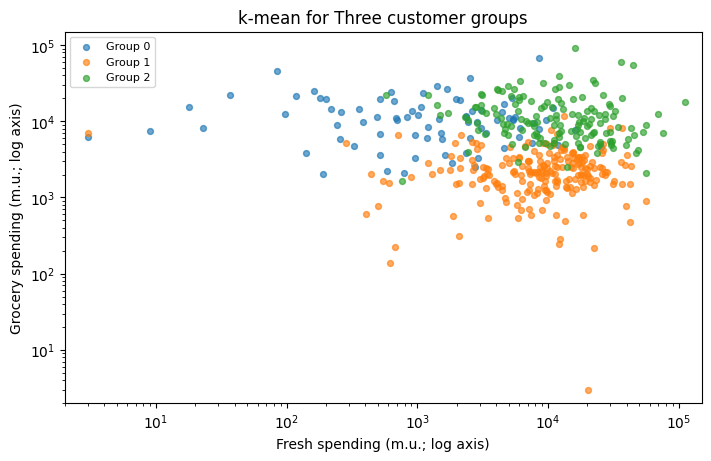

In [36]:
# Display the K-means result.
show_groups(kmeans_labels, "k-mean for Three customer groups")

**Question 1a:** Describe two contrasting purchasing profiles in the K-means result. Give each a short descriptive name and support each with two category medians. What might an account manager be able to learn from one of these groups?

> A grocery-focused group (81 customers) had median fresh consumption of 1,454 and grocery spending of 10,487, whereas a fresh-focused group (212 customers) had medians of 9,635 and 2,151, according to the K-means model. These variations could be used by an account manager to customize ratings according to whether a client spends more on fresh or grocery-type items.

**Question 1b:** Why do the K-means groups appear to overlap in the Fresh-versus-Grocery plot even though the model assigns each customer to one group?

> Because K-means assigns every customer using all six spending criteria, although the plot only displays two of them, the groups overlap in the Fresh-versus-Grocery plot. For instance, Groups 1 and 2 have comparable Fresh medians (9,635 and 12,126) and are mostly divided by Milk and Detergents_Paper, which is not represented in this figure.

## 2. Hierarchical Clustering: A Different Three-Group Summary

Perform agglomerative clustering on `X` using `linkage` with the `complete` method and Euclidean distance, naming the result `customer_tree`. Then use `cut_tree` to assign labels for three clusters and name the result `hierarchical_labels`. Use `.ravel()` to flatten the one-column array returned by `cut_tree` into a one-dimensional array of labels.

Use `show_groups` to display the results. Then run the provided code to show a truncated dendrogram, starting with 24 leaves (`p=24`). Its default colors need not match the three-group cut.

In [9]:
customer_tree = linkage(X, method="complete", metric="euclidean")
hierarchical_labels = cut_tree(customer_tree, n_clusters=3).ravel()
# Build the complete-linkage tree and extract three-group labels.

hierarchical for Three customer groups : category medians in original monetary units


,Customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
group,,,,,,,
0,402,8645.5,3798.0,5163.5,1597.0,952.0,1061.5
1,5,13569.0,346.0,245.0,2077.0,9.0,860.0
2,33,2787.0,727.0,1533.0,937.0,96.0,127.0


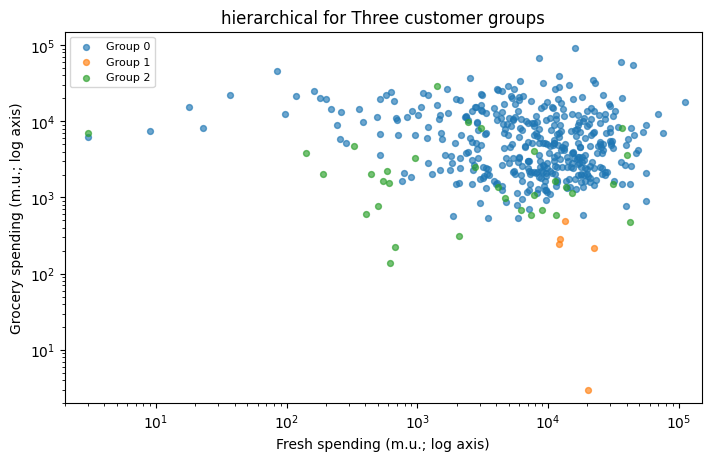

In [37]:
# Display the hierarchical result.
show_groups(hierarchical_labels, "hierarchical for Three customer groups")

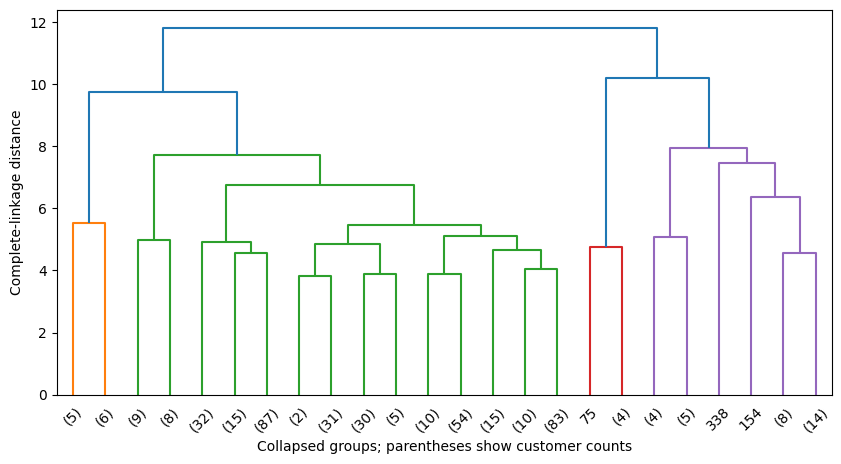

In [38]:
from scipy.cluster.hierarchy import dendrogram

if customer_tree is None:
    print("Build customer_tree before displaying the dendrogram.")
else:
    fig, ax = plt.subplots(figsize=(10, 5))
    dendrogram(
        customer_tree,
        truncate_mode="lastp",
        p=24,
        show_leaf_counts=True,
        ax=ax,
    )
    ax.set_ylabel("Complete-linkage distance")
    ax.set_xlabel("Collapsed groups; parentheses show customer counts")
    plt.show()

In [40]:
print(customer_tree[-3:,2])

[ 9.73232123 10.18025989 11.79820924]


**Question 2a:** Describe the smallest hierarchical group’s purchasing profile using its size and two spending medians. Then use the largest group’s size to explain a limitation of this three-group summary.

>The smallest hierarchical group contains only 5 customers, with a median Fresh spend of 13,569 but a Grocery spend of just 245, while the largest group holds 402 of 440 customers (about 91%). The three-group solution therefore puts nearly everyone into one profile and tells an account manager very little about how most customers differ.

**Question 2b:** Using the dendrogram, identify an approximate height at which a horizontal cut would produce three groups. What does that height measure?

> Since it lies between the two highest subtree merges at roughly 9.73 and 10.18, a horizontal cut at about 10 results in three groupings. The greatest standardized Euclidean distance between any two customers in the two clusters being combined is represented by that height, which is known as the complete-linkage distance.

## 3. DBSCAN: Dense Groups and Unassigned Customers

Create and fit `dbscan_small` on `X` with radius 0.8 and `min_samples=8`. Retrieve its labels as `small_labels` then use `show_groups` and `density_summary` to display the results.

In [24]:
dbscan_small = DBSCAN(eps = 0.8, min_samples=8)
small_labels = dbscan_small.fit_predict(X)
# Fit DBSCAN at radius 0.8, retrieve labels, and display the result.
if small_labels is not None:
    density_summary(small_labels)
    # Summarize the radius-0.8 assignments.

Repeat the fit with radius **1.2**, keeping `min_samples=8` and `X` unchanged. Save the fitted object as `dbscan_large` and its labels as `large_labels`. Use `show_groups` to display the result, then run the supplied comparison table.

DBSCAN radius 1.2 : category medians in original monetary units


,Customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
group,,,,,,,
Noise,85,5396.0,4753.0,6869.0,839.0,477.0,522.0
0,355,8797.0,3504.0,4523.0,1730.0,850.0,1000.0


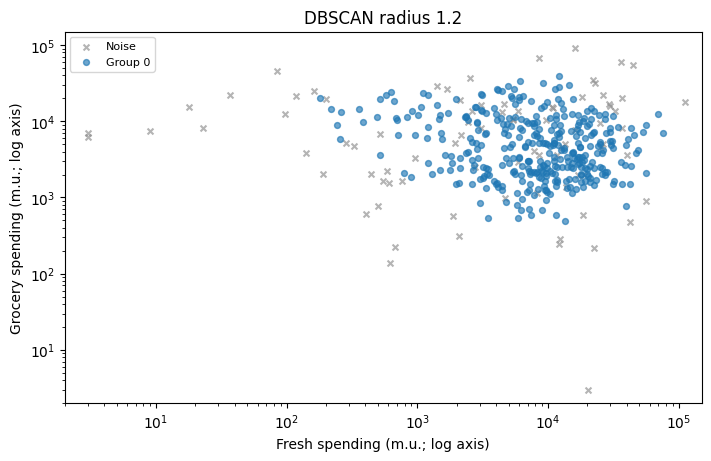

In [29]:
dbscan_large = DBSCAN(eps = 1.2, min_samples=8)
large_labels = dbscan_large.fit_predict(X)
if small_labels is not None:
  show_groups(large_labels, "DBSCAN radius 1.2")
# Fit DBSCAN at radius 1.2, retrieve labels, and display the result.

In [30]:
if small_labels is None or large_labels is None:
    print("Fit both DBSCAN models to compare the two radii.")
else:
    comparison = pd.DataFrame(
        [density_summary(small_labels), density_summary(large_labels)],
        index=["Radius 0.8", "Radius 1.2"],
    )
    display(comparison)

,Groups (excluding noise),Customers in groups,Noise customers
Radius 0.8,2,147,293
Radius 1.2,1,355,85


**Question 3a:** What tradeoff do the two DBSCAN radii show between assigning customers to groups and obtaining distinct purchasing profiles? Use the assigned-customer counts and the spending tables.

> DBSCAN classified 293 as noise and divided 147 out of 440 clients (33%) into two categories at radius 0.8. It allocated 355 (81%) at radius 1.2, but only to one group with 85 noise. Although the bigger radius increases coverage, it reduces the number of ways to differentiate customers by collapsing the structure into a single broad group.

**Question 3b:** Should customers labeled noise be excluded from account reviews? Explain what that label tells you and what it does not.

>

## 4. Gaussian Mixtures: Overlapping Purchasing Profiles

Create and fit a Gaussian mixture named `mixture` on `X` with three components, full covariance, 10 initializations, and `random_state=7130`. Print its convergence status, retrieve `mixture_labels` and `memberships`, and use `show_groups` to display the result. Then run the supplied customer-membership table.

converged: True
Gaussian Mixture : category medians in original monetary units


,Customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
group,,,,,,,
0,150,5474.0,7690.5,11722.0,990.0,5068.5,1355.5
1,66,2612.5,3536.0,5018.0,943.5,286.0,273.5
2,224,11082.0,1985.5,2474.5,2471.5,380.0,921.5


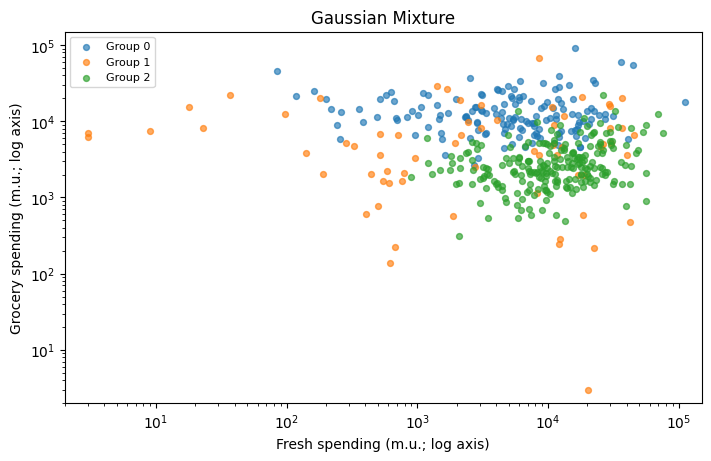

In [34]:
mixture = GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=7130).fit(X)
mixture_labels = mixture.predict(X)
memberships = mixture.predict_proba(X)
# Fit the Gaussian mixture, check convergence, and retrieve both outputs.
# Display the Gaussian-mixture result.
print("converged:", mixture.converged_)
show_groups(mixture_labels, "Gaussian Mixture")

In the spending table, Group j summarizes customers whose hard label is Component j. Its medians describe those assigned customers, not the fitted Gaussian mean.

In [33]:
if memberships is None or mixture_labels is None:
    print("Retrieve mixture labels and probabilities to inspect customer memberships.")
else:
    membership_table = pd.DataFrame(
        memberships, index=customers.index,
        columns=[f"Component {j}" for j in range(mixture.n_components)],
    )
    membership_table["Hard label"] = mixture_labels
    print("Two customers' original spending:")
    display(customers.loc[[50, 275], FEATURES])
    print("Their relative memberships and hard labels:")
    display(membership_table.loc[[50, 275]].round(3))

Two customers' original spending:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
customer_id,,,,,,
50,4967,21412,28921,1798,13583,1163
275,894,1703,1841,744,759,1153


Their relative memberships and hard labels:


,Component 0,Component 1,Component 2,Hard label
customer_id,,,,
50,0.999,0.001,0.000,0
275,0.306,0.261,0.432,2


**Question 4a:** Which customer, 50 or 275, has the less decisive Gaussian-mixture assignment? Quote its membership probabilities and describe its two leading components using their purchasing profiles.

> Replace this text with your answer to 4a.

**Question 4b:** What information would an account manager lose by receiving only this customer’s hard label? How might retaining the probabilities change the review?

> Replace this text with your answer to 4b.

## 5. Experiment with the Clustering Microscope

Use the [HW3B Clustering Microscope](https://raw.githubusercontent.com/olearydj/INSY7130/main/homework/hw3b/hw3b-clustering-microscope.py) to explore the same customers and six-feature representation. See the [quickstart](https://github.com/olearydj/INSY7130/blob/main/homework/hw3b/microscope-quickstart.md) for launching it. Change model settings to refit; change plot axes or select customers to inspect the existing fit. The plot and selected-versus-all summaries appear side by side. Try settings freely, but report only one three-setting comparison below. Record findings in this notebook; no separate microscope submission is required.

**Question 5a:** Choose one clustering method and one setting in the HW3B microscope. Compare the homework setting with two alternatives, keeping all other model settings fixed. Record the three settings and what changed in customer counts, purchasing profiles, noise, or membership ambiguity. A compact table or short paragraph is sufficient.

> Replace this text with your answer to 5a.

**Question 5b:** Which finding remained useful across your settings, and which depended on the setting? Use a rectangle or lasso selection to inspect a purchasing pattern: report the selected customer count and one selected-versus-all spending comparison. Explain what an account manager could reasonably learn from your experiment. Agreement across settings is a valid finding; you do not need to declare a best algorithm.

> Replace this text with your answer to 5b.

## Check and Submit

Submit one completed `.ipynb` notebook with your code, answers to Questions 1a–5b, displayed tables and figures, and assistance disclosure. Restart the runtime and run all cells in order before downloading. Check that your explanations match your results and that all five purchasing-profile displays and the dendrogram are present. You do not need to submit the CSV separately.

| Evaluation | Points |
| --- | ---: |
| K-means application and purchasing-profile interpretation | 2.0 |
| Hierarchical application and interpretation of the cut | 2.0 |
| DBSCAN comparison, customer coverage, and noise interpretation | 2.0 |
| GMM outputs and membership interpretation | 2.0 |
| Experiment and evidence-based interpretation | 1.5 |
| Reproducibility and assistance disclosure | 0.5 |
| **Total** | **10.0** |

Short, accurate responses are sufficient. A table of results does not replace the requested interpretation. Different descriptive names and defensible comparisons are welcome.

You may use course materials, documentation, and LLM assistance for understanding and debugging. This is individual work. Your explanations must be your own, and you must be able to explain or revise your code and reasoning. Identify material assistance and how you checked it, or write `None`.

**Assistance disclosure:**

> Replace this text with your disclosure.

**Optional, ungraded feedback:** Approximately how much active time did you spend, excluding breaks? Which part took the most effort, and was anything unclear?

> Optional feedback.